## Phần 1 - Chuẩn bị thư viện, đọc, chuẩn hóa và ghép dữ liệu dự báo

### 1.1 Import thư viện và thiết lập thư mục dữ liệu, kết quả

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

WEATHER_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "weather_clean.csv"
PROPHET_PRED_PATH = PROJECT_ROOT / "results" / "prophet" / "Prophet_Forecast_2026.csv"
LIGHTGBM_PRED_PATH = PROJECT_ROOT / "results" / "lightgbm" / "lightgbm_backtest.csv"

OUTPUT_DIR = PROJECT_ROOT / "results" / "comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Đã khởi tạo thư viện và thư mục kết quả:", OUTPUT_DIR)

Đã khởi tạo thư viện và thư mục kết quả: D:\NCKH\results\comparison


### 1.2 Đọc và kiểm tra sơ bộ dữ liệu dự báo của hai mô hình

In [2]:
prophet_raw = pd.read_csv(PROPHET_PRED_PATH)
lightgbm_raw = pd.read_csv(LIGHTGBM_PRED_PATH)

print("Các cột Prophet:", prophet_raw.columns.tolist())
print("Các cột LightGBM:", lightgbm_raw.columns.tolist())

print("\nKích thước Prophet:", prophet_raw.shape)
print("Kích thước LightGBM:", lightgbm_raw.shape)

display(prophet_raw.head())
display(lightgbm_raw.head())

Các cột Prophet: ['date', 'prophet_forecast', 'actual']
Các cột LightGBM: ['date', 'y_pred', 'y_true']

Kích thước Prophet: (181, 3)
Kích thước LightGBM: (181, 3)


,date,prophet_forecast,actual
0,2026-01-01,4.413749,1.9
1,2026-01-02,4.280541,1.5
2,2026-01-03,4.051407,-0.3
3,2026-01-04,3.866952,-1.0
4,2026-01-05,3.642115,-4.3


,date,y_pred,y_true
0,2026-01-01,4.5169,1.9
1,2026-01-02,4.5991,1.5
2,2026-01-03,3.7823,-0.3
3,2026-01-04,3.8010,-1.0
4,2026-01-05,3.8295,-4.3


### 1.3 Chuẩn hóa dữ liệu, kiểm tra ngày trùng và ghép dự báo cùng ngày

In [3]:
# Chuẩn hóa kết quả Prophet
prophet = prophet_raw.rename(columns={
    "prophet_forecast": "y_pred",
    "actual": "y_true"
}).copy()

# Chuẩn hóa kết quả LightGBM
lightgbm = lightgbm_raw.copy()

# Chỉ giữ các cột cần thiết
required_cols = ["date", "y_true", "y_pred"]

prophet = prophet[required_cols]
lightgbm = lightgbm[required_cols]

for data in [prophet, lightgbm]:
    data["date"] = pd.to_datetime(data["date"], errors="coerce")
    data["y_true"] = pd.to_numeric(data["y_true"], errors="coerce")
    data["y_pred"] = pd.to_numeric(data["y_pred"], errors="coerce")

    data.dropna(subset=required_cols, inplace=True)
    data.sort_values("date", inplace=True)
    data.reset_index(drop=True, inplace=True)

# Kiểm tra ngày trùng
assert not prophet["date"].duplicated().any(), \
    "Prophet có ngày trùng!"

assert not lightgbm["date"].duplicated().any(), \
    "LightGBM có ngày trùng!"

# Ghép theo ngày, chỉ giữ ngày có kết quả từ cả hai mô hình
comparison = prophet.merge(
    lightgbm,
    on="date",
    how="inner",
    suffixes=("_prophet", "_lightgbm"),
    validate="one_to_one"
)

# Kiểm tra nhiệt độ thực tế phải giống nhau giữa hai file
comparison["actual_difference"] = (
    comparison["y_true_prophet"]
    - comparison["y_true_lightgbm"]
).abs()

assert np.allclose(
    comparison["y_true_prophet"],
    comparison["y_true_lightgbm"],
    atol=1e-6
), "Nhiệt độ thực tế giữa hai file không khớp!"

comparison = comparison.rename(
    columns={"y_true_prophet": "y_true"}
)

comparison = comparison.drop(
    columns=["y_true_lightgbm", "actual_difference"]
)

print("Số ngày Prophet:", len(prophet))
print("Số ngày LightGBM:", len(lightgbm))
print("Số ngày ghép thành công:", len(comparison))
print("Từ ngày:", comparison["date"].min().date())
print("Đến ngày:", comparison["date"].max().date())

display(comparison.head())

Số ngày Prophet: 181
Số ngày LightGBM: 181
Số ngày ghép thành công: 181
Từ ngày: 2026-01-01
Đến ngày: 2026-06-30


,date,y_true,y_pred_prophet,y_pred_lightgbm
0,2026-01-01,1.9,4.413749,4.5169
1,2026-01-02,1.5,4.280541,4.5991
2,2026-01-03,-0.3,4.051407,3.7823
3,2026-01-04,-1.0,3.866952,3.8010
4,2026-01-05,-4.3,3.642115,3.8295


## Phần 2 - Xây dựng mô hình cơ sở và đánh giá bằng MAE, RMSE, Bias

Để đánh giá và so sánh hiệu quả dự báo của các mô hình, nghiên cứu sử dụng ba chỉ số MAE, RMSE và Bias:

- MAE (Mean Absolute Error): Sai số tuyệt đối trung bình giữa nhiệt độ dự báo và nhiệt độ thực tế. MAE càng thấp thì dự báo càng gần với giá trị thực tế.

- RMSE (Root Mean Squared Error): Căn bậc hai của trung bình bình phương sai số dự báo. Chỉ số này nhạy hơn với các sai số lớn; RMSE càng thấp thì kết quả dự báo nhìn chung càng tốt.

- Bias (Mean Error): Sai số trung bình có xét dấu giữa nhiệt độ dự báo và nhiệt độ thực tế. Bias dương cho thấy mô hình có xu hướng dự báo cao hơn thực tế, còn Bias âm cho thấy mô hình có xu hướng dự báo thấp hơn thực tế. Bias càng gần 0 thì mức độ sai lệch có hệ thống càng nhỏ. Tuy nhiên, không nên sử dụng Bias làm tiêu chí duy nhất để lựa chọn mô hình.

### 2.1 Xây dựng hàm tính MAE, RMSE, Bias và số ngày đánh giá

In [4]:
def calculate_metrics(y_true, y_pred):
    """Tính các chỉ số đánh giá dự báo nhiệt độ."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Bias": np.mean(y_pred - y_true),
        "So_ngay": len(y_true)
    }

# Tính chỉ số cho Prophet
metrics_prophet = calculate_metrics(
    comparison["y_true"],
    comparison["y_pred_prophet"]
)

# Tính chỉ số cho LightGBM
metrics_lightgbm = calculate_metrics(
    comparison["y_true"],
    comparison["y_pred_lightgbm"]
)

metrics_df = pd.DataFrame([
    {"Mo_hinh": "Prophet", **metrics_prophet},
    {"Mo_hinh": "LightGBM", **metrics_lightgbm}
])

metrics_df[["MAE", "RMSE", "Bias"]] = (
    metrics_df[["MAE", "RMSE", "Bias"]].round(4)
)

display(metrics_df)

,Mo_hinh,MAE,RMSE,Bias,So_ngay
0,Prophet,3.3428,4.1488,-1.0800,181
1,LightGBM,3.3047,4.1665,0.0533,181


### 2.2 Seasonal Naive – mô hình dự báo cơ sở

Seasonal Naive là mô hình dự báo cơ sở, sử dụng nhiệt độ thực tế của cùng ngày lịch năm trước làm giá trị dự báo cho ngày cần dự báo. Mô hình này giúp đánh giá liệu Prophet và LightGBM có cải thiện độ chính xác so với một phương pháp dự báo đơn giản dựa trên tính mùa vụ hay không.

### Tạo dự báo Seasonal Naive từ nhiệt độ cùng ngày năm trước

In [5]:
weather = pd.read_csv(WEATHER_DATA_PATH)

# 1. Chuẩn hóa dữ liệu
weather["date"] = pd.to_datetime(
    weather["date"], errors="coerce"
).dt.normalize()

weather["tavg"] = pd.to_numeric(
    weather["tavg"], errors="coerce"
)

weather = weather.dropna(subset=["date", "tavg"]).copy()

# 2. Kiểm tra ngày trùng trong dữ liệu gốc
duplicate_count = weather["date"].duplicated().sum()
print("Số bản ghi ngày trùng:", duplicate_count)

# Nếu một ngày có nhiều bản ghi, lấy nhiệt độ trung bình ngày đó
weather_daily = (
    weather.groupby("date", as_index=False)["tavg"]
    .mean()
)

# 3. Chuẩn hóa ngày trong bảng so sánh
comparison["date"] = pd.to_datetime(
    comparison["date"], errors="coerce"
).dt.normalize()

if "y_pred_seasonal_naive" in comparison.columns:
    comparison = comparison.drop(
        columns=["y_pred_seasonal_naive"]
    )

# 4. Với mỗi ngày dự báo, tìm nhiệt độ cùng ngày năm trước
comparison["seasonal_source_date"] = comparison["date"].map(
    lambda d: d - pd.DateOffset(years=1)
)

seasonal_source = weather_daily.rename(
    columns={
        "date": "seasonal_source_date",
        "tavg": "y_pred_seasonal_naive"
    }
)

# 5. Ghép dữ liệu: nhiều ngày mục tiêu có thể tham chiếu
comparison = comparison.merge(
    seasonal_source,
    on="seasonal_source_date",
    how="left",
    validate="many_to_one"
)

# 6. Kiểm tra kết quả
print(
    "Số ngày có dự báo Seasonal Naive:",
    comparison["y_pred_seasonal_naive"].notna().sum()
)

print(
    "Số ngày thiếu dự báo Seasonal Naive:",
    comparison["y_pred_seasonal_naive"].isna().sum()
)

display(
    comparison[
        ["date", "y_true", "y_pred_seasonal_naive"]
    ].head(10)
)

Số bản ghi ngày trùng: 0
Số ngày có dự báo Seasonal Naive: 181
Số ngày thiếu dự báo Seasonal Naive: 0


,date,y_true,y_pred_seasonal_naive
0,2026-01-01,1.9,3.4
1,2026-01-02,1.5,3.2
2,2026-01-03,-0.3,1.4
3,2026-01-04,-1.0,0.1
4,2026-01-05,-4.3,1.5
5,2026-01-06,-4.0,9.9
6,2026-01-07,-3.3,5.7
7,2026-01-08,0.4,3.1
8,2026-01-09,4.8,5.0
9,2026-01-10,0.1,1.5


### 2.3 Xây dựng tập đánh giá chung và so sánh chỉ số của ba mô hình

In [6]:
evaluation = comparison.dropna(
    subset=[
        "y_true",
        "y_pred_prophet",
        "y_pred_lightgbm",
        "y_pred_seasonal_naive"
    ]
).copy()

models = {
    "Prophet": "y_pred_prophet",
    "LightGBM": "y_pred_lightgbm",
    "Seasonal Naive": "y_pred_seasonal_naive"
}

rows = []

for model_name, pred_col in models.items():
    result = calculate_metrics(
        evaluation["y_true"],
        evaluation[pred_col]
    )

    rows.append({
        "Mo_hinh": model_name,
        **result
    })

metrics_all = pd.DataFrame(rows)

display(metrics_all.round(4))

,Mo_hinh,MAE,RMSE,Bias,So_ngay
0,Prophet,3.3428,4.1488,-1.0800,181
1,LightGBM,3.3047,4.1665,0.0533,181
2,Seasonal Naive,3.5685,4.5816,-0.3044,181


## Phần 3 - Trực quan hóa nhiệt độ thực tế và kết quả dự báo

### So sánh nhiệt độ thực tế với dự báo của ba mô hình

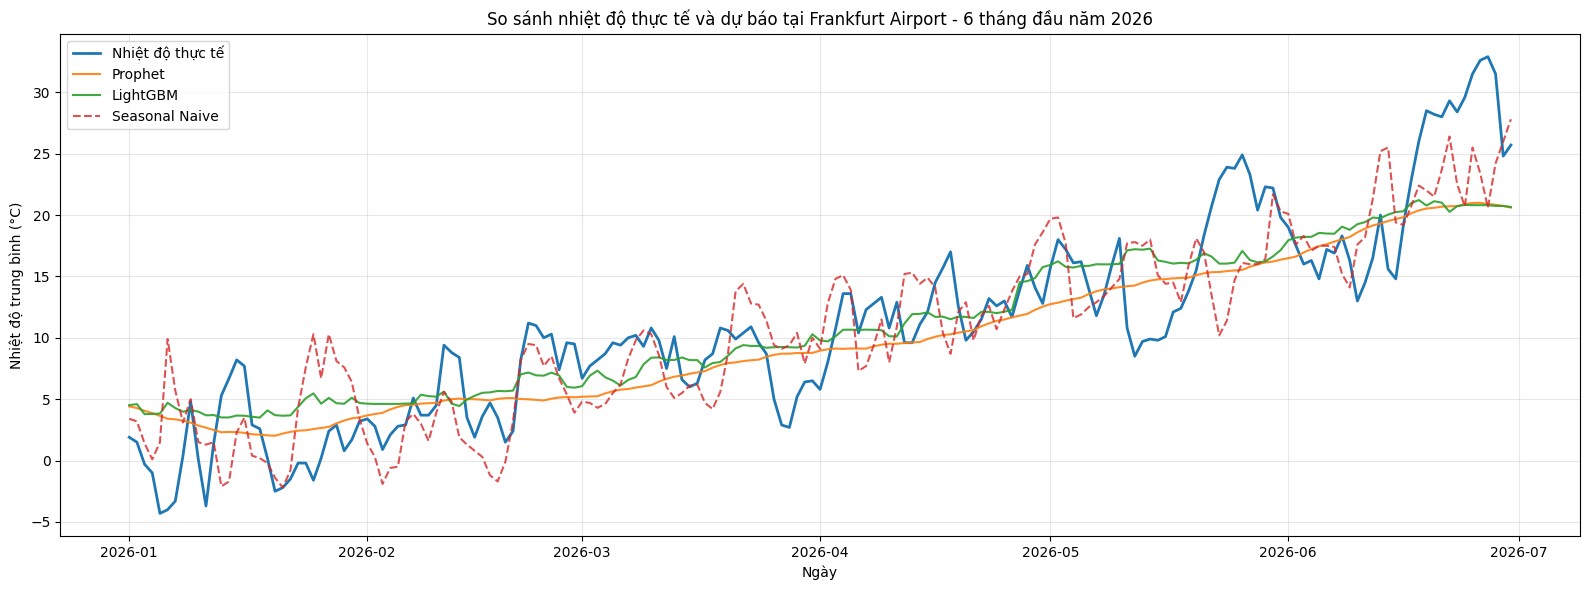

In [7]:
plt.figure(figsize=(16, 6))

plt.plot(
    evaluation["date"],
    evaluation["y_true"],
    label="Nhiệt độ thực tế",
    linewidth=2
)

plt.plot(
    evaluation["date"],
    evaluation["y_pred_prophet"],
    label="Prophet",
    alpha=0.9
)

plt.plot(
    evaluation["date"],
    evaluation["y_pred_lightgbm"],
    label="LightGBM",
    alpha=0.9
)

plt.plot(
    evaluation["date"],
    evaluation["y_pred_seasonal_naive"],
    label="Seasonal Naive",
    alpha=0.8,
    linestyle="--"
)

plt.title(
    "So sánh nhiệt độ thực tế và dự báo "
    "tại Frankfurt Airport - 6 tháng đầu năm 2026"
)
plt.xlabel("Ngày")
plt.ylabel("Nhiệt độ trung bình (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "actual_vs_forecast.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Phần 4 - Phân tích sai số dự báo theo tháng và theo ngày

### 4.1 Tính các chỉ số MAE và RMSE theo tháng cho ba mô hình

In [8]:
monthly_data = evaluation.copy()

monthly_data["year_month"] = (
    monthly_data["date"].dt.to_period("M").astype(str)
)

monthly_rows = []

for month, group in monthly_data.groupby("year_month"):
    row = {"Thang": month, "So_ngay": len(group)}

    for model_name, pred_col in models.items():
        row[f"{model_name}_MAE"] = mean_absolute_error(
            group["y_true"],
            group[pred_col]
        )

        row[f"{model_name}_RMSE"] = np.sqrt(
            mean_squared_error(
                group["y_true"],
                group[pred_col]
            )
        )

    monthly_rows.append(row)

monthly_metrics = pd.DataFrame(monthly_rows)

numeric_cols = monthly_metrics.select_dtypes(
    include="number"
).columns

monthly_metrics[numeric_cols] = (
    monthly_metrics[numeric_cols].round(4)
)

display(monthly_metrics)

,Thang,So_ngay,Prophet_MAE,Prophet_RMSE,LightGBM_MAE,LightGBM_RMSE,Seasonal Naive_MAE,Seasonal Naive_RMSE
0,2026-01,31,3.3164,3.9244,4.1185,4.6402,4.2774,5.5817
1,2026-02,28,2.6656,3.1974,2.4820,2.7688,2.5214,3.0558
2,2026-03,31,2.7006,3.0675,2.2346,2.7348,2.9452,3.4346
3,2026-04,30,2.2673,2.8512,1.7543,2.1723,2.8033,3.4502
4,2026-05,31,4.2437,4.8541,4.1705,4.9728,4.5935,5.7905
5,2026-06,30,4.8106,6.0161,4.9932,6.1099,4.1633,5.1956


### 4.2 Trực quan hóa MAE theo tháng

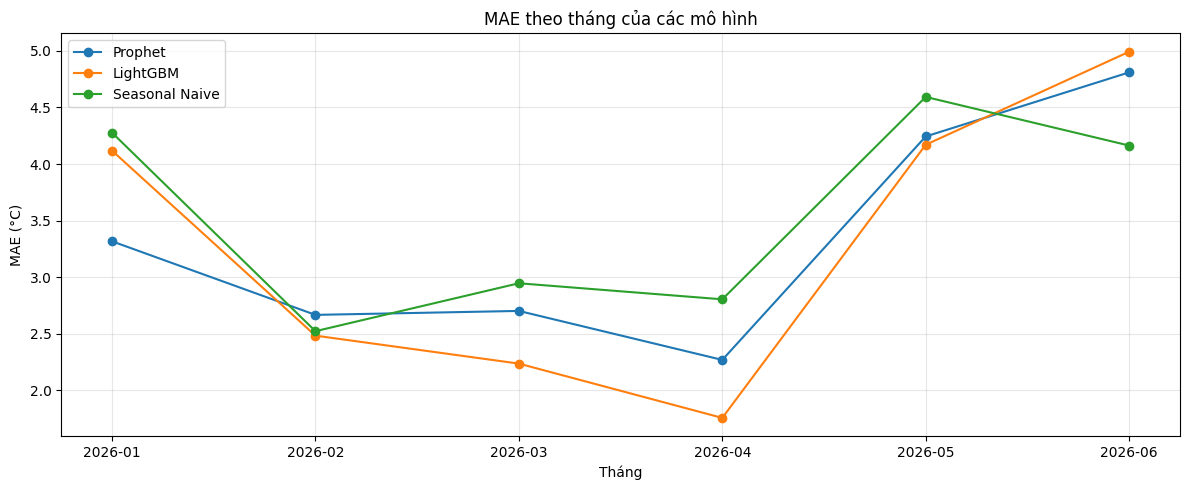

In [9]:
plt.figure(figsize=(12, 5))

for model_name in models:
    plt.plot(
        monthly_metrics["Thang"],
        monthly_metrics[f"{model_name}_MAE"],
        marker="o",
        label=model_name
    )

plt.title("MAE theo tháng của các mô hình")
plt.xlabel("Tháng")
plt.ylabel("MAE (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_mae.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 4.3 Phân tích sai số dự báo theo ngày của ba mô hình

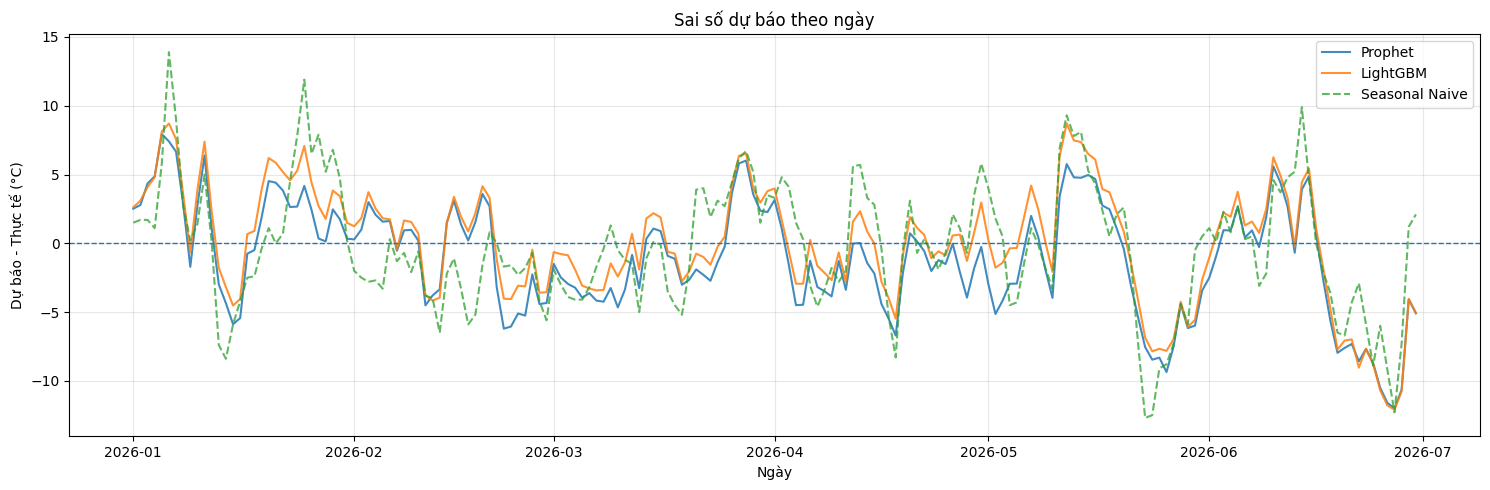

In [10]:
error_data = evaluation[["date", "y_true"]].copy()

error_data["error_prophet"] = (
    evaluation["y_pred_prophet"] - evaluation["y_true"]
)

error_data["error_lightgbm"] = (
    evaluation["y_pred_lightgbm"] - evaluation["y_true"]
)

error_data["error_seasonal_naive"] = (
    evaluation["y_pred_seasonal_naive"] - evaluation["y_true"]
)

plt.figure(figsize=(15, 5))

plt.plot(
    error_data["date"],
    error_data["error_prophet"],
    label="Prophet",
    alpha=0.85
)

plt.plot(
    error_data["date"],
    error_data["error_lightgbm"],
    label="LightGBM",
    alpha=0.85
)


plt.plot(
    error_data["date"],
    error_data["error_seasonal_naive"],
    label="Seasonal Naive",
    alpha=0.75,
    linestyle="--"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Sai số dự báo theo ngày")
plt.xlabel("Ngày")
plt.ylabel("Dự báo - Thực tế (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "daily_forecast_errors.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Phần 5 - Xếp hạng và lựa chọn mô hình dự báo tốt nhất
Dùng MAE làm tiêu chí chính, RMSE làm tiêu chí phụ.

### Xếp hạng mô hình theo MAE, RMSE và xác định mô hình được chọn

Quy tắc lựa chọn:
 1. Ưu tiên MAE thấp hơn.
 2. Nếu MAE bằng nhau, ưu tiên RMSE thấp hơn.
 3. Chỉ xét trên cùng tập ngày đánh giá.

In [11]:
ranked_models = metrics_all.sort_values(
    by=["MAE", "RMSE"],
    ascending=[True, True]
).reset_index(drop=True)

ranked_models.insert(
    0, "Xep_hang",
    range(1, len(ranked_models) + 1)
)

display(ranked_models.round(4))

# Mô hình đứng đầu theo tiêu chí đã định
selected_model = ranked_models.iloc[0]["Mo_hinh"]

print("Mô hình được lựa chọn:", selected_model)
print("Số ngày dùng để đánh giá:", len(evaluation))

,Xep_hang,Mo_hinh,MAE,RMSE,Bias,So_ngay
0,1,LightGBM,3.3047,4.1665,0.0533,181
1,2,Prophet,3.3428,4.1488,-1.0800,181
2,3,Seasonal Naive,3.5685,4.5816,-0.3044,181


Mô hình được lựa chọn: LightGBM
Số ngày dùng để đánh giá: 181


## Phần 6 - Xuất bảng so sánh và dữ liệu dự báo

### 6.1 Xuất bảng chỉ số so sánh và xếp hạng mô hình

In [12]:
# Kiểm tra dữ liệu đầu vào
required_columns = [
    "date",
    "y_true",
    "y_pred_prophet",
    "y_pred_lightgbm",
    "y_pred_seasonal_naive"
]

missing_columns = [
    col for col in required_columns
    if col not in evaluation.columns
]

if missing_columns:
    raise ValueError(
        f"Thiếu các cột cần thiết: {missing_columns}"
    )

if evaluation.empty:
    raise ValueError("Không có dữ liệu đánh giá.")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Khai báo cột dự báo của từng mô hình
model_columns = {
    "Prophet": "y_pred_prophet",
    "LightGBM": "y_pred_lightgbm",
    "Seasonal Naive": "y_pred_seasonal_naive"
}

metric_rows = []

for model_name, prediction_column in model_columns.items():
    result = calculate_metrics(
        evaluation["y_true"],
        evaluation[prediction_column]
    )

    metric_rows.append({
        "Mo_hinh": model_name,
        "MAE": result["MAE"],
        "RMSE": result["RMSE"],
        "Bias": result["Bias"],
        "So_ngay": result["So_ngay"]
    })

metrics_export = pd.DataFrame(metric_rows)

# Xếp hạng theo MAE tăng dần, RMSE là tiêu chí phụ
metrics_export = metrics_export.sort_values(
    by=["MAE", "RMSE"],
    ascending=[True, True]
).reset_index(drop=True)

metrics_export.insert(
    0,
    "Xep_hang",
    range(1, len(metrics_export) + 1)
)

# Xác định mô hình tốt nhất
selected_model = metrics_export.iloc[0]["Mo_hinh"]

metrics_export["Duoc_chon"] = (
    metrics_export["Mo_hinh"] == selected_model
)

metrics_file = (
    OUTPUT_DIR / "model_comparison_metrics.csv"
)

metrics_export.to_csv(
    metrics_file,
    index=False,
    encoding="utf-8-sig",
    float_format="%.6f"
)

# Hiển thị kết quả
print("ĐÃ XUẤT FILE 1: BẢNG CHỈ SỐ SO SÁNH")
print("Đường dẫn:", metrics_file.resolve())
print("Mô hình được chọn:", selected_model)
print("Tiêu chí chọn: MAE thấp nhất, RMSE là tiêu chí phụ")
print("Số ngày đánh giá:", len(evaluation))

print("\n===== BẢNG CHỈ SỐ VÀ XẾP HẠNG =====")
display(metrics_export.round(4))

ĐÃ XUẤT FILE 1: BẢNG CHỈ SỐ SO SÁNH
Đường dẫn: D:\NCKH\results\comparison\model_comparison_metrics.csv
Mô hình được chọn: LightGBM
Tiêu chí chọn: MAE thấp nhất, RMSE là tiêu chí phụ
Số ngày đánh giá: 181

===== BẢNG CHỈ SỐ VÀ XẾP HẠNG =====


,Xep_hang,Mo_hinh,MAE,RMSE,Bias,So_ngay,Duoc_chon
0,1,LightGBM,3.3047,4.1665,0.0533,181,True
1,2,Prophet,3.3428,4.1488,-1.0800,181,False
2,3,Seasonal Naive,3.5685,4.5816,-0.3044,181,False


### 6.2 Xuất dữ liệu dự báo ghép theo ngày và các cột sai số

In [13]:
# Kiểm tra dữ liệu đầu vào
required_columns = [
    "date",
    "y_true",
    "y_pred_prophet",
    "y_pred_lightgbm",
    "y_pred_seasonal_naive"
]

missing_columns = [
    col for col in required_columns
    if col not in evaluation.columns
]

if missing_columns:
    raise ValueError(
        f"Thiếu các cột cần thiết: {missing_columns}"
    )

if evaluation.empty:
    raise ValueError("Không có dữ liệu đánh giá.")

# Lấy các cột cần bàn giao
final_comparison = evaluation[
    required_columns
].copy()

# Sắp xếp dữ liệu theo ngày
final_comparison = (
    final_comparison
    .sort_values("date")
    .reset_index(drop=True)
)

# Khai báo cột dự báo của từng mô hình
model_columns = {
    "Prophet": "y_pred_prophet",
    "LightGBM": "y_pred_lightgbm",
    "Seasonal Naive": "y_pred_seasonal_naive"
}

# Tính sai số và sai số tuyệt đối cho cả 3 mô hình
for model_name, prediction_column in model_columns.items():
    suffix = model_name.lower().replace(" ", "_")

    final_comparison[f"error_{suffix}"] = (
        final_comparison[prediction_column]
        - final_comparison["y_true"]
    )

    final_comparison[f"abs_error_{suffix}"] = (
        final_comparison[f"error_{suffix}"].abs()
    )

# Chuẩn hóa định dạng ngày
final_comparison["date"] = pd.to_datetime(
    final_comparison["date"]
).dt.strftime("%Y-%m-%d")

# Xuất file CSV
predictions_file = (
    OUTPUT_DIR / "comparison_predictions.csv"
)

final_comparison.to_csv(
    predictions_file,
    index=False,
    encoding="utf-8-sig",
    float_format="%.6f"
)

# Hiển thị kết quả
print("ĐÃ XUẤT FILE 2: DỮ LIỆU DỰ BÁO VÀ SAI SỐ")
print("Đường dẫn:", predictions_file.resolve())

print(
    "Giai đoạn đánh giá:",
    final_comparison["date"].min(),
    "đến",
    final_comparison["date"].max()
)

print("Số ngày đánh giá chung:", len(final_comparison))

print("\n===== XEM TRƯỚC DỮ LIỆU DỰ BÁO =====")
display(final_comparison.head(10))

ĐÃ XUẤT FILE 2: DỮ LIỆU DỰ BÁO VÀ SAI SỐ
Đường dẫn: D:\NCKH\results\comparison\comparison_predictions.csv
Giai đoạn đánh giá: 2026-01-01 đến 2026-06-30
Số ngày đánh giá chung: 181

===== XEM TRƯỚC DỮ LIỆU DỰ BÁO =====


,date,y_true,y_pred_prophet,y_pred_lightgbm,y_pred_seasonal_naive,error_prophet,abs_error_prophet,error_lightgbm,abs_error_lightgbm,error_seasonal_naive,abs_error_seasonal_naive
0,2026-01-01,1.9,4.413749,4.5169,3.4,2.513749,2.513749,2.6169,2.6169,1.5,1.5
1,2026-01-02,1.5,4.280541,4.5991,3.2,2.780541,2.780541,3.0991,3.0991,1.7,1.7
2,2026-01-03,-0.3,4.051407,3.7823,1.4,4.351407,4.351407,4.0823,4.0823,1.7,1.7
3,2026-01-04,-1.0,3.866952,3.8010,0.1,4.866952,4.866952,4.8010,4.8010,1.1,1.1
4,2026-01-05,-4.3,3.642115,3.8295,1.5,7.942115,7.942115,8.1295,8.1295,5.8,5.8
5,2026-01-06,-4.0,3.407637,4.7104,9.9,7.407637,7.407637,8.7104,8.7104,13.9,13.9
6,2026-01-07,-3.3,3.361476,4.2766,5.7,6.661476,6.661476,7.5766,7.5766,9.0,9.0
7,2026-01-08,0.4,3.251326,3.9773,3.1,2.851326,2.851326,3.5773,3.5773,2.7,2.7
8,2026-01-09,4.8,3.089990,4.1191,5.0,-1.710010,1.710010,-0.6809,0.6809,0.2,0.2
9,2026-01-10,0.1,2.853205,3.9879,1.5,2.753205,2.753205,3.8879,3.8879,1.4,1.4
